# Part 2 — Exploratory Data Analysis with Spark
**Project:** Financial Forecasting Frontier: Distributed ML  
**Contribution:** Individual — Suman  
**Domain:** Banking marketing analytics  
**Data:** Official AlmaBetter bank.csv, 4,521 client/contact records, 17 columns.  
**Objective:** Explain distributed data processing and estimate term-deposit subscription. This is an educational sample, not a credit eligibility or fraud system.  
The supplied EDA/ML templates guide the summary → business problem → data → transformations → analysis/model → conclusion structure. Part-specific questions below follow the official question documents.


## Project summary and business problem
Explore which client groups and contact strategies are associated with subscription. Use Spark DataFrames and SQL for computation, collecting only small outputs for charts. Rates describe associations in this sample; they do not establish causes. The sample is small enough for local analysis, but the same distributed transformations run on two worker containers here.

In [1]:
APP_NAME='Banking-Spark-EDA'
import sys
sys.path.insert(0, '/workspace')
from banking.common import *
prepare_dirs()
spark = session(APP_NAME)
df = load_bank(spark).repartition(4).cache()
print('Spark version:', spark.version)
print('Master:', spark.sparkContext.master)
print('Data partitions:', df.rdd.getNumPartitions())


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/20 18:55:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.3
Master: spark://spark-master:7077


Data partitions: 4


## Q1. Know your data: loading, schema, summary, missing values and duplicates

In [2]:
df.show(5, truncate=False)
df.printSchema()
df.select('age','balance','duration','campaign','pdays','previous').summary().show()
n=df.count()
missing={c:df.filter(F.col(c).isNull()).count() for c in df.columns}
print('Shape:', (n,len(df.columns)), 'Duplicates:', n-df.dropDuplicates().count())
print('Nulls:',missing)
print('Unknown categories:')
df.select([F.sum((F.col(c)=='unknown').cast('int')).alias(c) for c in CAT]).show()
df.groupBy('y').count().show()
assert n==4521 and set(df.columns)==set(SCHEMA.fieldNames())
save_json('data_quality.json',{'rows':n,'columns':len(df.columns),'duplicates':n-df.dropDuplicates().count(),'nulls':missing,'target':rows(df.groupBy('y').count())})


+---+-----------+--------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|job        |marital |education|default|balance|housing|loan|contact |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+-----------+--------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|26 |blue-collar|married |primary  |no     |5116   |yes    |no  |cellular|22 |jul  |246     |3       |-1   |0       |unknown |no |
|38 |management |single  |tertiary |no     |427    |yes    |no  |cellular|6  |may  |17      |3       |169  |2       |failure |no |
|33 |technician |single  |tertiary |no     |696    |no     |yes |cellular|5  |feb  |193     |1       |176  |8       |failure |no |
|50 |management |married |tertiary |no     |78     |yes    |no  |cellular|14 |jan  |218     |3       |161  |9       |other   |no |
|44 |admin.     |divorced|secondary|no     |432    |no     |no  |cellular|9  |feb  

26/10/20 18:57:57 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+------------------+-----------------+------------------+------------------+
|summary|               age|           balance|          duration|         campaign|             pdays|          previous|
+-------+------------------+------------------+------------------+-----------------+------------------+------------------+
|  count|              4521|              4521|              4521|             4521|              4521|              4521|
|   mean| 41.17009511170095|1422.6578190665782|263.96129174961294|2.793629727936297|39.766644547666445|0.5425790754257908|
| stddev|10.576210958711261|3009.6381424673423|  259.856632624682|3.109806660188576|100.12112444301664|1.6935623506071225|
|    min|                19|             -3313|                 4|                1|                -1|                 0|
|    25%|                33|                69|               104|                1|                -1|                 0|
|    50%|       

Shape: (4521, 17) Duplicates: 0
Nulls: {'age': 0, 'job': 0, 'marital': 0, 'education': 0, 'default': 0, 'balance': 0, 'housing': 0, 'loan': 0, 'contact': 0, 'day': 0, 'month': 0, 'duration': 0, 'campaign': 0, 'pdays': 0, 'previous': 0, 'poutcome': 0, 'y': 0}
Unknown categories:


+---+-------+---------+-------+-------+----+-------+-----+--------+
|job|marital|education|default|housing|loan|contact|month|poutcome|
+---+-------+---------+-------+-------+----+-------+-----+--------+
| 38|      0|      187|      0|      0|   0|   1324|    0|    3705|
+---+-------+---------+-------+-------+----+-------+-----+--------+



+---+-----+
|  y|count|
+---+-----+
| no| 4000|
|yes|  521|
+---+-----+



### Variables and data limitations
Age is in years; balance is average yearly account balance; housing/loan/default are yes/no flags; duration is call duration in seconds; pdays=-1 means no previous contact. Unknown categories are retained. No customer ID, loan amount, complete date, or year is provided. All y values must be yes/no.

## Q2. Filtering and quarter
Map month abbreviations to month numbers; do not invent a date or year.

In [3]:
months=['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
month_map=F.create_map(*[v for i,m in enumerate(months,1) for v in (F.lit(m),F.lit(i))])
df=(df.withColumn('month_num',month_map[F.lower(F.col('month'))])
      .withColumn('quarter',F.ceil(F.col('month_num')/3).cast('int')))
df.filter(F.col('balance')>1000).select('age','job','balance','month','quarter').show(10)
print('Balance > 1000:',df.filter(F.col('balance')>1000).count())
df.groupBy('month','month_num','quarter').count().orderBy('month_num').show(12)


+---+-----------+-------+-----+-------+
|age|        job|balance|month|quarter|
+---+-----------+-------+-----+-------+
| 26|blue-collar|   5116|  jul|      3|
| 41| management|  10758|  jun|      2|
| 52| management|   1339|  aug|      3|
| 49| technician|   3726|  aug|      3|
| 31|  housemaid|  26965|  apr|      2|
| 31| management|   4945|  aug|      3|
| 55|     admin.|   1102|  may|      2|
| 39| technician|   1043|  aug|      3|
| 33| technician|   9305|  apr|      2|
| 54|    unknown|   1157|  may|      2|
+---+-----------+-------+-----+-------+
only showing top 10 rows



Balance > 1000: 1481


+-----+---------+-------+-----+
|month|month_num|quarter|count|
+-----+---------+-------+-----+
|  jan|        1|      1|  148|
|  feb|        2|      1|  222|
|  mar|        3|      1|   49|
|  apr|        4|      2|  293|
|  may|        5|      2| 1398|
|  jun|        6|      2|  531|
|  jul|        7|      3|  706|
|  aug|        8|      3|  633|
|  sep|        9|      3|   52|
|  oct|       10|      4|   80|
|  nov|       11|      4|  389|
|  dec|       12|      4|   20|
+-----+---------+-------+-----+



## Q3. GroupBy and aggregation

In [4]:
job_stats=df.groupBy('job').agg(F.count('*').alias('clients'),F.avg('balance').alias('avg_balance'),F.percentile_approx('age',0.5).alias('median_age')).orderBy(F.desc('avg_balance'))
job_stats.show(truncate=False)
df.filter(F.col('y')=='yes').groupBy('marital').count().show()
save_json('eda_job_stats.json',rows(job_stats))


+-------------+-------+------------------+----------+
|job          |clients|avg_balance       |median_age|
+-------------+-------+------------------+----------+
|retired      |230    |2319.191304347826 |59        |
|housemaid    |112    |2083.8035714285716|49        |
|management   |969    |1766.9287925696594|38        |
|entrepreneur |168    |1645.125          |41        |
|student      |84     |1543.8214285714287|26        |
|unknown      |38     |1501.7105263157894|49        |
|self-employed|183    |1392.4098360655737|40        |
|technician   |768    |1330.99609375     |38        |
|admin.       |478    |1226.73640167364  |38        |
|services     |417    |1103.9568345323742|37        |
|unemployed   |128    |1089.421875       |41        |
|blue-collar  |946    |1085.161733615222 |39        |
+-------------+-------+------------------+----------+



+--------+-----+
| marital|count|
+--------+-----+
| married|  277|
|divorced|   77|
|  single|  167|
+--------+-----+



## Q4. Age-group UDF
The required Python UDF uses <30, 30–60 inclusive, and >60. A built-in CASE expression is preferable in production because it avoids Python serialization overhead.

In [5]:
@F.udf(T.StringType())
def age_group(age):
    if age is None: return 'unknown'
    return '<30' if age<30 else ('30-60' if age<=60 else '>60')
df=df.withColumn('age_group',age_group('age'))
df.groupBy('age_group').count().show()


+---------+-----+
|age_group|count|
+---------+-----+
|    30-60| 3912|
|      <30|  482|
|      >60|  127|
+---------+-----+



## Q5. Education subscription rate and default prevalence
The default field describes existing credit default. Calling this a future loan-default probability would overstate what the data supports. Counts accompany rates to expose small samples.

In [6]:
education=df.groupBy('education').agg(F.count('*').alias('clients'),F.sum((F.col('y')=='yes').cast('int')).alias('subscribers')).withColumn('subscription_pct',100*F.col('subscribers')/F.col('clients')).orderBy(F.desc('subscription_pct'))
education.show()
defaults=df.groupBy('job').agg(F.count('*').alias('clients'),F.sum((F.col('default')=='yes').cast('int')).alias('default_count')).withColumn('default_pct',100*F.col('default_count')/F.col('clients')).orderBy(F.desc('default_pct'),F.desc('clients'))
defaults.show(3)
save_json('eda_education.json',rows(education))
save_json('eda_default_rates.json',rows(defaults))


+---------+-------+-----------+------------------+
|education|clients|subscribers|  subscription_pct|
+---------+-------+-----------+------------------+
| tertiary|   1350|        193|14.296296296296296|
|secondary|   2306|        245|10.624457935819601|
|  unknown|    187|         19| 10.16042780748663|
|  primary|    678|         64|  9.43952802359882|
+---------+-------+-----------+------------------+



+-------------+-------+-------------+-----------------+
|          job|clients|default_count|      default_pct|
+-------------+-------+-------------+-----------------+
| entrepreneur|    168|            7|4.166666666666667|
|   unemployed|    128|            3|          2.34375|
|self-employed|    183|            4|2.185792349726776|
+-------------+-------+-------------+-----------------+
only showing top 3 rows



## Q6. String transformations

In [7]:
df=df.withColumn('job_marital',F.concat_ws('_','job','marital')).withColumn('contact_upper',F.upper('contact'))
df.select('job_marital','contact_upper').show(8,truncate=False)


+-------------------+-------------+
|job_marital        |contact_upper|
+-------------------+-------------+
|blue-collar_married|CELLULAR     |
|management_single  |CELLULAR     |
|technician_single  |CELLULAR     |
|management_married |CELLULAR     |
|admin._divorced    |CELLULAR     |
|management_married |CELLULAR     |
|blue-collar_single |UNKNOWN      |
|management_married |CELLULAR     |
+-------------------+-------------+
only showing top 8 rows



## Q7. Visualization
The question asks for a Pandas conversion. This sample has only 4,521 rows; the explicit row limit prevents accidental driver exhaustion on a larger dataset. For production, aggregate in Spark first, as the chart below does.

Matplotlib is building the font cache; this may take a moment.


Pandas sample shape: (4521, 22)


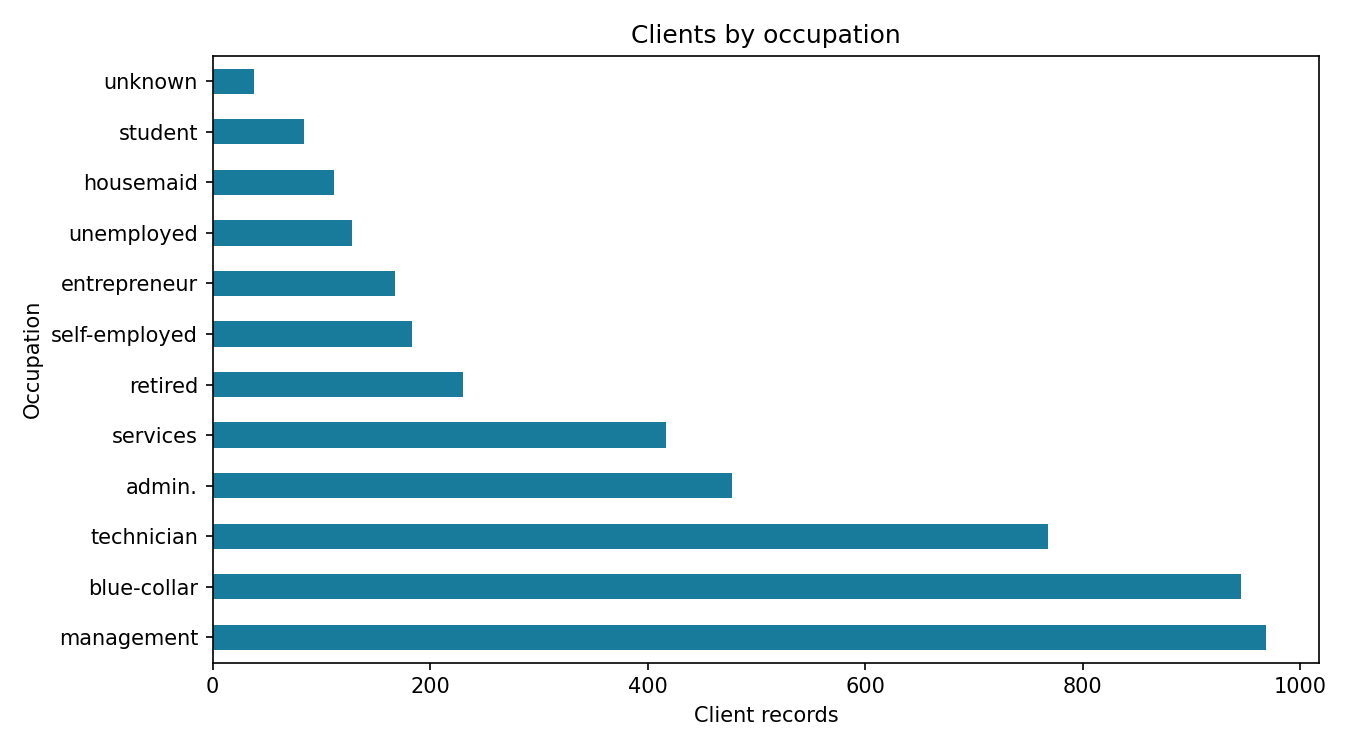

In [8]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image
assert n<=10000, 'Collect aggregated results instead of the full dataset at scale.'
sample_pdf=df.toPandas()
print('Pandas sample shape:',sample_pdf.shape)
plot=df.groupBy('job').count().orderBy(F.desc('count')).toPandas()
ax=plot.plot.barh(x='job',y='count',legend=False,color='#197b9c',figsize=(9,5))
ax.set(title='Clients by occupation',xlabel='Client records',ylabel='Occupation')
plt.tight_layout();plt.savefig('/workspace/reports/job_counts.png',dpi=150);display(Image('/workspace/reports/job_counts.png'));plt.close()


## Q8. Contact volumes, campaign success and duration

In [9]:
monthly=df.groupBy('month','month_num').agg(F.count('*').alias('contacts'),F.avg((F.col('y')=='yes').cast('double')).alias('subscription_rate')).orderBy(F.desc('contacts'))
monthly.show(12)
duration=df.groupBy('y').agg(F.count('*').alias('clients'),F.avg('duration').alias('avg_call_seconds'))
duration.show()
save_json('eda_monthly.json',rows(monthly))
save_json('eda_duration.json',rows(duration))


+-----+---------+--------+-------------------+
|month|month_num|contacts|  subscription_rate|
+-----+---------+--------+-------------------+
|  may|        5|    1398|0.06652360515021459|
|  jul|        7|     706|0.08640226628895184|
|  aug|        8|     633|0.12480252764612954|
|  jun|        6|     531|0.10357815442561205|
|  nov|       11|     389|0.10025706940874037|
|  apr|        4|     293|0.19112627986348124|
|  feb|        2|     222|0.17117117117117117|
|  jan|        1|     148|0.10810810810810811|
|  oct|       10|      80|             0.4625|
|  sep|        9|      52| 0.3269230769230769|
|  mar|        3|      49|0.42857142857142855|
|  dec|       12|      20|               0.45|
+-----+---------+--------+-------------------+



+---+-------+-----------------+
|  y|clients| avg_call_seconds|
+---+-------+-----------------+
| no|   4000|         226.3475|
|yes|    521|552.7428023032629|
+---+-------+-----------------+



## Q9. Age/balance correlation
Pearson correlation measures linear association and is sensitive to outliers. It does not imply causation.

In [10]:
correlation=df.stat.corr('age','balance')
print('Age vs balance Pearson r:',correlation)
save_json('eda_correlation.json',{'age_balance_pearson':correlation})


Age vs balance Pearson r: 0.08382014224477755


## Q10. Credit default proportions

+-------+-----+------------------+
|default|count|               pct|
+-------+-----+------------------+
|     no| 4445| 98.31895598318955|
|    yes|   76|1.6810440168104401|
+-------+-----+------------------+



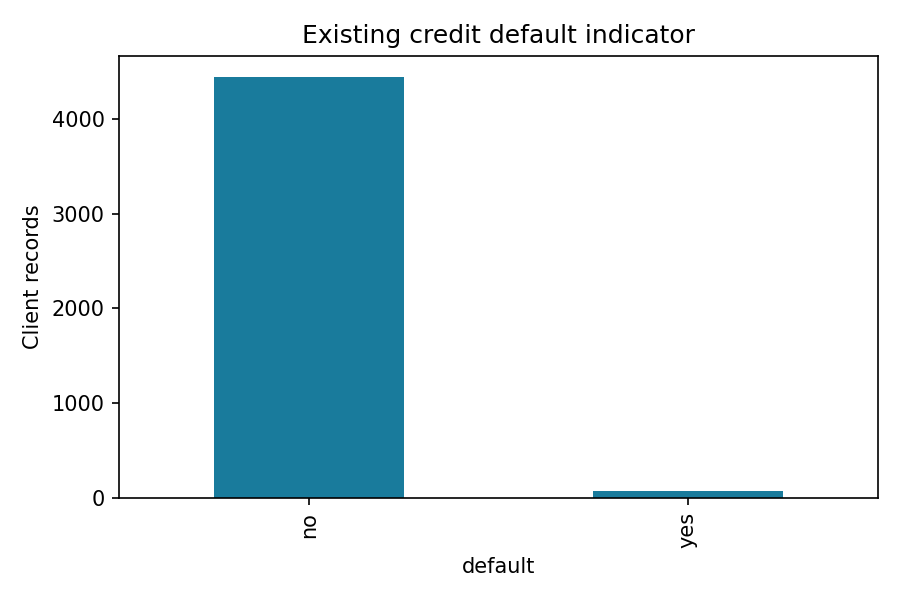

In [11]:
default_counts=df.groupBy('default').count().withColumn('pct',100*F.col('count')/n)
default_counts.show()
plot=default_counts.toPandas()
plot.plot.bar(x='default',y='count',legend=False,color='#197b9c',figsize=(6,4))
plt.title('Existing credit default indicator');plt.ylabel('Client records');plt.tight_layout()
plt.savefig('/workspace/reports/default_counts.png',dpi=150);display(Image('/workspace/reports/default_counts.png'));plt.close()


## Q11. Contact-method subscription rate

In [12]:
contact=df.groupBy('contact').agg(F.count('*').alias('contacts'),F.avg((F.col('y')=='yes').cast('double')).alias('subscription_rate')).orderBy(F.desc('subscription_rate'))
contact.show()
save_json('eda_contact.json',rows(contact))


+---------+--------+-------------------+
|  contact|contacts|  subscription_rate|
+---------+--------+-------------------+
|telephone|     301| 0.1461794019933555|
| cellular|    2896|  0.143646408839779|
|  unknown|    1324|0.04607250755287009|
+---------+--------+-------------------+



## Q12. Spark SQL and business interpretation

In [13]:
df.createOrReplaceTempView('bank_clients')
spark.sql('SELECT age_group,COUNT(*) AS clients,AVG(balance) AS avg_balance FROM bank_clients GROUP BY age_group ORDER BY age_group').show()
spark.sql('SELECT job,COUNT(*) AS clients FROM bank_clients GROUP BY job ORDER BY clients DESC LIMIT 5').show()
print('Busiest month:',monthly.first().asDict())
print('Highest education subscription rate:',education.first().asDict())
print('Most successful recorded contact category:',contact.first().asDict())
print('Interpretation: compare counts and rates, not rates alone. These are sample associations, not causal campaign recommendations.')
df.unpersist()
spark.stop()


+---------+-------+------------------+
|age_group|clients|       avg_balance|
+---------+-------+------------------+
|    30-60|   3912|1426.8755112474437|
|      <30|    482|1058.0954356846473|
|      >60|    127|2676.3543307086616|
+---------+-------+------------------+



+-----------+-------+
|        job|clients|
+-----------+-------+
| management|    969|
|blue-collar|    946|
| technician|    768|
|     admin.|    478|
|   services|    417|
+-----------+-------+



Busiest month: {'month': 'may', 'month_num': 5, 'contacts': 1398, 'subscription_rate': 0.06652360515021459}


Highest education subscription rate: {'education': 'tertiary', 'clients': 1350, 'subscribers': 193, 'subscription_pct': 14.296296296296296}


Most successful recorded contact category: {'contact': 'telephone', 'contacts': 301, 'subscription_rate': 0.1461794019933555}
Interpretation: compare counts and rates, not rates alone. These are sample associations, not causal campaign recommendations.


## Conclusion
Spark performs filtering, grouping and SQL across partitions. Only bounded data is collected for plots. Larger call durations among subscribers can be useful retrospectively, but duration must not enter a pre-call model. The next part fits preprocessing only on training data and evaluates an untouched test split.